# The leakage-safe fit of the monotone scorecard, read back from the Taiwan cards

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- state the leakage-safe design of the C01 fit: what is split off, what each slice may be used for, and what is fitted on the training slice only;
- read the monotone binning the fit learned, check its constraints (monotone default rate, bins of at least 5% of the cards) on the committed counts, and see that every count comes from the 16,800 training cards;
- place raw cards into the learned bins by hand and recompute their scores from the points table, exactly, with no model object;
- compare the fitted scorecard with a one-variable baseline on the 9,000 held-out cards, with the engine's tests, and say what a refit from the raw file needs.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))


riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The same case as notebook 01: C01, the UCI Taiwan credit-card file (Yeh, 2009; CC BY 4.0, licence class `mirror-allowed`, https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients), 30,000 cards. The fit itself runs in the pipeline (`data-pipeline/pipeline/model/scorecard.py`, with `optbinning`, `statsmodels` and `scikit-learn`) on the raw file, which lives outside the repository under the data root. This notebook reads what the fit committed and does not rerun it, so it needs neither the raw file nor those libraries:

- `data/derived/C01/models-taiwan.json`: the split, the variables with their constraints, the learned bins, the coefficients and the table of points with the training counts of every bin.
- `data/derived/C01/holdout.json`: the 50-card sample with the raw inputs, the points and the score, and the committed test rows of the 9,000 held-out cards.

The next cell loads both files.

In [2]:
# Load the two committed files (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C01"
models = json.loads((derived / "models-taiwan.json").read_text(encoding="utf-8"))
holdout = json.loads((derived / "holdout.json").read_text(encoding="utf-8"))

fit = models["fit"]
card = next(m for m in models["model"] if m["id"] == "P1-scorecard")["details"]
table = card["points_table"]
print("seed of the bake:", fit["seed"], "| rows in the file:", fit["split"]["train"]["n"] + fit["split"]["calibration"]["n"] + fit["split"]["holdout"]["n"])
print("baked by riskvalidation", models["provenance"]["riskvalidation_version"], "| installed", rv.__version__)


seed of the bake: 42 | rows in the file: 30000
baked by riskvalidation 0.4.3 | installed 0.8.1


## Method

### Step 1: the leakage-safe split

The research rules for every scoring fit (the product's research basis, dossier 04, "universal leakage rules") say that every transform is **fitted on the training slice only** (binning, WoE, imputation, scaling, variable selection), that a calibration map is fitted on a **separate** calibration slice, never on the test slice, and that nothing is resampled before calibration is measured. C01 applies them with one stratified split with a fixed seed: 56% to fit (16,800 cards), 14% to calibrate the challengers (4,200) and a locked holdout of 30% (9,000) that no fitting step has seen. The scorecard itself uses the training slice only; the calibration slice serves the challengers of notebook 06. The next cell prints the three slices and checks that the stratification worked: the same default rate in each.

In [3]:
# Print the three slices of the split with their default rates
split = fit["split"]
total = sum(split[name]["n"] for name in ("train", "calibration", "holdout"))
print(f"{'slice':12s} {'cards':>8s} {'share':>7s} {'defaults':>9s} {'rate':>8s}")
for name in ("train", "calibration", "holdout"):
    part = split[name]
    print(f"{name:12s} {part['n']:8d} {part['n'] / total:7.2f} {part['defaults']:9d} {part['default_rate']:8.4f}")
rates = [split[name]["default_rate"] for name in ("train", "calibration", "holdout")]
print("spread of the default rate across the slices:", f"{max(rates) - min(rates):.5f}")
print("cross-validation inside the training slice:", split["folds"]["k"], "folds, repeated", split["folds"]["repeats"], "times")


slice           cards   share  defaults     rate
train           16800    0.56      3716   0.2212
calibration      4200    0.14       929   0.2212
holdout          9000    0.30      1991   0.2212
spread of the default rate across the slices: 0.00003
cross-validation inside the training slice: 5 folds, repeated 2 times


### Step 2: the variables and their constraints

The scorecard starts from the 20 variables of the file. Each carries a **monotone constraint**, the direction in which the default rate is allowed to move along the bins: +1 ascending (more months late, more default), -1 descending (a higher credit limit or a larger payment, less default), 0 left free. A monotone binning is what keeps the scorecard explainable: a bigger limit never buys a worse score. The next cell prints the variables, their units and their constraint, from the committed fit.

In [4]:
# Print each variable with its unit and its monotone constraint
units = {"": "", "NT dollars": "NT dollars", "months of delay": "months of delay"}
direction = {1: "ascending", -1: "descending", 0: "free"}
for variable in fit["features"]:
    print(f"{variable['name']:10s} {units[variable['unit']]:16s} {direction[variable['monotone']]}")


LIMIT_BAL  NT dollars       descending
EDUCATION                   free
PAY_0      months of delay  ascending
PAY_2      months of delay  ascending
PAY_3      months of delay  ascending
PAY_4      months of delay  ascending
PAY_5      months of delay  ascending
PAY_6      months of delay  ascending
BILL_AMT1  NT dollars       free
BILL_AMT2  NT dollars       free
BILL_AMT3  NT dollars       free
BILL_AMT4  NT dollars       free
BILL_AMT5  NT dollars       free
BILL_AMT6  NT dollars       free
PAY_AMT1   NT dollars       descending
PAY_AMT2   NT dollars       descending
PAY_AMT3   NT dollars       descending
PAY_AMT4   NT dollars       descending
PAY_AMT5   NT dollars       descending
PAY_AMT6   NT dollars       descending


### Step 3: the learned bins and their checks

For each kept variable the fit learned cut points on the training slice. The points table commits, for every bin, the cards and the defaults it held on that slice. Two checks follow from the constraints, and both can be made on the counts:

- every bin holds at least 5% of the training cards (`min_bin_size` of the fit parameters);
- the default rate moves along the bins in the direction of the constraint.

Counts that add up to 16,800 cards for each variable also show that the bins were learned on the training slice and nowhere else. The next cell checks the three things for the 13 kept variables.

In [5]:
# Check the three properties of the learned bins on the committed counts
constraint = {v["name"]: v["monotone"] for v in fit["features"]}
min_share = 0.05
print(f"{'variable':10s} {'bins':>6s} {'cards':>8s} {'smallest share':>15s} {'at least 5%':>12s} {'monotone':>10s}")
for name in card["features"]:
    rows = [r for r in table if r["feature"] == name and r["count"] > 0]
    cards = sum(r["count"] for r in rows)
    smallest = min(r["count"] for r in rows) / cards
    steps = np.diff([r["event_rate"] for r in rows])
    holds = bool((steps >= 0).all()) if constraint[name] == 1 else bool((steps <= 0).all())
    print(f"{name:10s} {len(rows):6d} {cards:8d} {smallest:15.4f} {str(smallest >= min_share):>12s} {str(holds):>10s}")
    assert cards == split["train"]["n"]
print("every variable adds up to the training slice:", split["train"]["n"], "cards")
print("bin size floor of the fit:", min_share)


variable     bins    cards  smallest share  at least 5%   monotone
LIMIT_BAL       8    16800          0.0609         True       True
PAY_0           4    16800          0.0930         True       True
PAY_2           2    16800          0.1495         True       True
PAY_3           3    16800          0.1414         True       True
PAY_4           3    16800          0.1179         True       True
PAY_5           3    16800          0.0983         True       True
PAY_6           3    16800          0.1032         True       True
PAY_AMT1        8    16800          0.0530         True       True
PAY_AMT2        8    16800          0.0501         True       True
PAY_AMT3        7    16800          0.0518         True       True
PAY_AMT4        7    16800          0.0506         True       True
PAY_AMT5        6    16800          0.0830         True       True
PAY_AMT6        7    16800          0.0973         True       True
every variable adds up to the training slice: 16800 cards
bin 

The cut points are in `details["bins"]` of the model. A bin is the half-open interval between two consecutive cut points, so a card falls in the bin given by how many cut points are at or below its value. The next cell prints the cut points of three variables.

In [6]:
# Print the cut points the fit learned for three variables
for name in ("PAY_0", "PAY_2", "LIMIT_BAL"):
    print(f"{name:10s} cut points:", card["bins"][name]["splits"])


PAY_0      cut points: [-1.5, 0.5, 1.5]
PAY_2      cut points: [1.5]
LIMIT_BAL  cut points: [45000.0, 75000.0, 105000.0, 145000.0, 165000.0, 245000.0, 375000.0]


### Step 4: place raw cards into the bins

The 50 cards of the sample come with their raw inputs. For each of the 13 variables the next cell counts the cut points at or below the card's value (`numpy.searchsorted` with `side="right"`, which is exactly the half-open rule above), reads the points of that row of the table, and gathers the 13 numbers of every card. The helper only looks a value up in a committed table; the binning itself was learned by the pipeline. Then it compares all 50 times 13 numbers with the point columns the pipeline stored for the same cards.

In [7]:
# Look up the points of every raw value in the committed table and compare with the stored point columns
sample = holdout["outputs"]["sample"]
y = np.array(sample["targets"])
stored_points = np.array(sample["scorecard_points"])


def locate_points(name, values):
    # The rows of this variable in bin order, and how many cut points are at or below each value
    rows = [r for r in table if r["feature"] == name]
    index = np.searchsorted(card["bins"][name]["splits"], values, side="right")
    return np.array([rows[i]["points"] for i in index])


rebuilt = np.column_stack([locate_points(name, np.array(sample["inputs"][name], dtype=float)) for name in card["features"]])
print("cards:", rebuilt.shape[0], "| variables:", rebuilt.shape[1])
print("point cells that differ from the stored ones:", int((rebuilt != stored_points).sum()), "of", rebuilt.size)


cards: 50 | variables: 13
point cells that differ from the stored ones: 0 of 650


### Step 5: the score is the sum, exactly

With the 13 numbers of each card, the score is their sum, and nothing else: no coefficient, no exponent and no model object is needed at the desk. The next cell sums the rebuilt points and compares them with the score the pipeline committed for the 50 cards. The same sum also gives the PD through the scale of notebook 01; here we only check the scores.

In [8]:
# Add the rebuilt points and compare the sums with the committed scores
score_rebuilt = rebuilt.sum(axis=1)
score_stored = np.array(sample["scorecard_score"])
print("scores that differ:", int((score_rebuilt != score_stored).sum()), "of", len(score_stored))
print("lowest and highest score of the sample:", int(score_rebuilt.min()), int(score_rebuilt.max()))
print("defaulters have a lower mean score:", round(float(score_rebuilt[y == 1].mean()), 1), "against", round(float(score_rebuilt[y == 0].mean()), 1))


scores that differ: 0 of 50
lowest and highest score of the sample: 446 572
defaulters have a lower mean score: 507.5 against 531.4


### Step 6: what the logistic step decided

The logistic step fixed one coefficient per variable. In the table of points, its effect on a card is the **spread of the points** of a variable: the points of its best bin minus the points of its worst bin, which is $\mathrm{Factor}\,|\beta_j|\,(\max_b \mathrm{WoE}_{j,b} - \min_b \mathrm{WoE}_{j,b})$. A variable with a wide spread can move a card's score a lot; one with a narrow spread hardly matters. The next cell computes the spread from the committed points table and draws it. It is the scorecard's own reading of "which variables drive the score", the number a credit officer would quote.

PAY_0      spread of points   58.5   beta  -0.7435
PAY_AMT2   spread of points   14.3   beta  -0.2768
LIMIT_BAL  spread of points   13.5   beta  -0.3135
PAY_AMT3   spread of points   10.5   beta  -0.2639
PAY_6      spread of points   10.3   beta  -0.2195
PAY_5      spread of points    9.9   beta  -0.1925
PAY_3      spread of points    7.5   beta  -0.1533
PAY_AMT1   spread of points    6.4   beta  -0.1378
PAY_AMT6   spread of points    5.2   beta  -0.1704
PAY_4      spread of points    4.7   beta  -0.0958
PAY_2      spread of points    4.3   beta  -0.0786
PAY_AMT4   spread of points    3.8   beta  -0.1114
PAY_AMT5   spread of points    2.6   beta  -0.0840


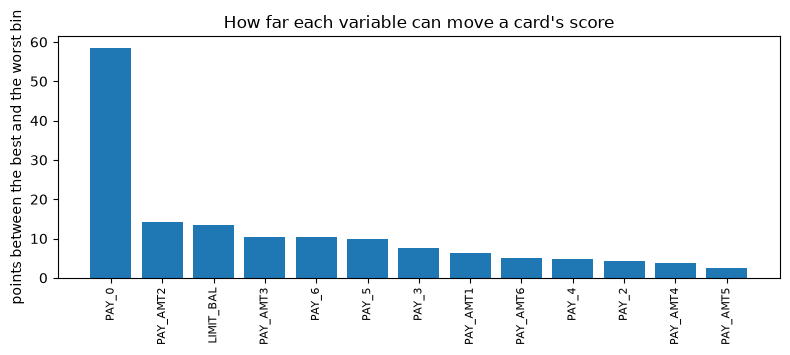

In [9]:
# Compute the spread of the points of each variable from the committed table and draw it
spread = {}
for name in card["features"]:
    pts = [r["points_raw"] for r in table if r["feature"] == name and r["count"] > 0]
    spread[name] = max(pts) - min(pts)
order = sorted(spread, key=lambda n: -spread[n])
for name in order:
    print(f"{name:10s} spread of points {spread[name]:6.1f}   beta {card['coefficients'][name]:8.4f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(range(len(order)), [spread[n] for n in order])
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=90, fontsize=8)
ax.set_ylabel("points between the best and the worst bin")
ax.set_title("How far each variable can move a card's score")
fig.tight_layout()
plt.show()


### Step 7: the fitted scorecard against a one-variable baseline

A fit is worth its complexity only if it beats something simpler. Rung P0 of the ladder is a one-variable scorecard on `PAY_0` alone (the same binning machinery, one variable). The engine's tests compare the two on the 9,000 held-out cards: the AUC and the Kolmogorov-Smirnov distance (the largest gap between the score distributions of defaulters and non-defaulters), and the DeLong test of the AUC difference for two models scored on the same cards (DeLong, DeLong and Clarke-Pearson, 1988). The 9,000 scores are not in the repository, only the committed rows, so the next cell reads those rows. It then calls the engine on the 50-card sample to show the same two functions at work.

In [10]:
# Read the committed rows of rung P0 (one variable) and P1 (the scorecard) on the 9,000 held-out cards
def committed_row(test_id, model_id):
    return next(t for t in holdout["tests"] if t["test_id"] == test_id and t["model_id"] == model_id and t["segment"] == "portfolio")


print(f"{'':14s} {'AUC':>8s} {'KS':>8s}")
for model_id in ("P0-single", "P1-scorecard"):
    print(f"{model_id:14s} {committed_row('disc.auc', model_id)['metric']:8.4f} {committed_row('disc.ks', model_id)['metric']:8.4f}")
delong = committed_row("disc.delong", "P0-single")
print("DeLong: AUC difference", round(delong["extras"]["difference"], 4), "| z", round(delong["statistic"], 2), "| p", format(delong["p_value"], ".3g"), "|", delong["light"])
print("committed by riskvalidation", holdout["provenance"]["riskvalidation_version"])


                    AUC       KS
P0-single        0.6917   0.3599
P1-scorecard     0.7587   0.3973
DeLong: AUC difference -0.067 | z -13.35 | p 1.26e-40 | red
committed by riskvalidation 0.4.3


The same two engine functions on the 50-card sample: the AUC and the KS distance of the scorecard's PD, and the AUC of the integer score alone (the sign is changed because a higher score means a lower risk).

In [11]:
# The same two engine functions on the 50-card sample, with the PD of the scorecard
from riskvalidation.validation import disc_auc, disc_ks

policy = rv.default_policy()
pd_card = np.array(sample["scorecard_pd"])
auc = disc_auc(pd_card, y, policy=policy, model_id="P1-scorecard")
ks = disc_ks(pd_card, y, policy=policy, model_id="P1-scorecard")
print("AUC:", round(auc.metric, 4), "| KS:", round(ks.metric, 4), "| cards:", auc.n, "| defaults:", auc.n_events)
print("the same ranking from the integer score alone:", round(disc_auc(-score_rebuilt.astype(float), y, policy=policy, model_id="P1-scorecard").metric, 4))


AUC: 0.7752 | KS: 0.5048 | cards: 50 | defaults: 15
the same ranking from the integer score alone: 0.7781


### Step 8: what a refit needs

Everything above is the fit read back. To refit it, the pipeline needs the raw file and the libraries the notebook environment does not carry (`optbinning==1.0.0`, `statsmodels==0.15.0`, `scikit-learn==1.9.1` and their dependencies, pinned in `data-pipeline/requirements.txt`). The documented route, from `docs/guides/01_fetch-and-bake.md`, is a sandbox bake that writes outside the repository and leaves `data/` untouched:

```bash
python data-pipeline/fetch.py uci-taiwan
python data-pipeline/run.py C01 --output <a temporary folder>
```

The canonical C01 bake takes about twelve minutes; fitting the scorecard alone takes seconds. A second bake from the same file and seed reproduces the committed artifacts byte for byte (the bake is a pure function of its inputs and the seed 42). The invariance of the fit to anything outside the training slice is gated by `tests/test_leakage.py`, which notebook 07 shows.

## Results

- **The split is stratified and the slices are disjoint in purpose.** The three slices share one default rate to the fourth decimal, 22.1%, so the holdout is a fair sample of the population the scorecard was fitted on. Nothing in the committed artifact lets the holdout leak into the fit: the counts of every one of the 13 variables add up to the 16,800 training cards.
- **The learned bins respect their constraints.** Every bin holds at least 5% of the training cards, and the default rate moves in the declared direction along the bins of all 13 variables. `PAY_0` has four bins and the repayment-status variables of earlier months only two or three; the amounts of payments have six to eight.
- **The points table reproduces the scores exactly.** From the raw inputs of the 50 cards and the cut points alone, all 650 point cells and all 50 scores match what the pipeline stored. This is the property that makes a scorecard auditable: no model object is needed to explain a score.
- **What the model weighs.** The spread of points is largest for the repayment status of the latest month (`PAY_0`, about 58 points between its best and worst bin) and then for the amount paid in August (`PAY_AMT2`, 14 points), the credit limit (13 points) and the other payment variables. Bill amounts do not appear: they were dropped on information value in notebook 01.
- **The fit beats the baseline.** Against the one-variable scorecard, the full scorecard raises the AUC from 0.692 to 0.759 and the KS from 0.360 to 0.397 on the 9,000 held-out cards, and the DeLong test rejects equal AUCs (p about 1e-40). The difference of 0.067 AUC points is the value of the other 12 variables.

What this notebook does not show: the standard errors and p-values of the logistic step. The committed artifact holds the coefficients and the signs, not the statistical table of the fit, and `statsmodels` is not in the notebook environment; the sign check (all coefficients negative) is the visible trace of that step. It does not refit, and it does not show the scorecard out of time: C01 is one snapshot of 2005, a limit that notebook 07 states as a finding.

## Summary

- The fit is leakage-safe by design: a stratified split with a fixed seed, bins and coefficients learned on the 16,800 training cards only, a separate calibration slice for the challengers, and a locked holdout.
- The learned bins obey their constraints, which can be checked on the committed counts: monotone default rate, at least 5% of the cards per bin.
- A scorecard is auditable: from raw values and the committed cut points, the table of points reproduces every score exactly, with no model object.
- The spread of points per variable shows what the scorecard weighs; the fitted scorecard beats the one-variable baseline on the held-out cards, with the engine's AUC, KS and DeLong tests.

**What to try next.** Pick another variable in Step 3 and read its bins and its points; then continue with notebook 03, which runs the validation battery on the whole ladder of models.

## References

- Navas-Palencia, G. (2020), Optimal binning: mathematical programming formulation. https://arxiv.org/abs/2001.08025
- Siddiqi, N. (2017), Intelligent Credit Scoring, 2nd ed., Wiley. https://doi.org/10.1002/9781119282396
- DeLong, E. R., DeLong, D. M. and Clarke-Pearson, D. L. (1988), Comparing the areas under two or more correlated receiver operating characteristic curves: a nonparametric approach, Biometrics 44(3). https://doi.org/10.2307/2531595
- Hanley, J. A. and McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Annex 1 (section 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
- This repository: `docs/guides/01_fetch-and-bake.md`, `docs/design/SDD.md` (the leakage-safe split of each case) and the pipeline's `data-pipeline/pipeline/model/scorecard.py`.